# MPC run overview and failed windows

- **Predictor** `mpc/core/predictor/bicycle.py`: the 12-state predictor, the thesis bicycle plus the four wheel speeds, with the plant's force laws.
- **OCP** `mpc/core/ocp.py`: Radau direct collocation (degree 3, 60 x 50 ms = 3 s), thesis Eq. 7.4 cost with its Ch. 3 example weights. Constraints: initial state, collocation, continuity, state/rate boxes and the lap-time OCP's track tube. No terminal constraint, no extras.
- **Track/reference**: the lap-time OCP's track (`laptime_core.track.Track`, smoothing 50), corridor (width - 1.0 - 0.2 m) and optimal solution (line, heading, speed x `speed_scale`).
- **Plant**: the double-wishbone plant; each update its state is projected to the 8 body states plus the measured wheel speeds, with combined slip recorded as a KPI.

Only **rejected windows** get detailed plots. Each was re-solved identically with an iteration recorder and saved in the `plotting/PlotHelpers.py` schema (`meta['lapTime']` holds the window objective; `s` is the predicted progress).

New run: set `RUN` (name, start/end, `ipopt_log=True` to save solver logs, `ipopt_print=5` to print them live) and `MPC_SETTINGS` in `mpc/workflows/run_mpc.py`, run `.\.venv\Scripts\python.exe -B -m mpc.workflows.run_mpc`; `RUN = None` below then picks it up.

In [1]:
%matplotlib inline
import sys, os
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..', '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT)
import matplotlib.pyplot as plt
from plotting import PlotHelpers
from mpc.core.helpers.plots import (Run, RESULTS, plot_track, plot_signals, plot_solver, plot_window_horizon,
                                    plot_prediction_error, plot_iteration_map)
from mpc.core.helpers.ocp_compare import (compare, summary_table, section_table, plot_times, plot_track_overlay,
                                          plot_traces, plot_sections)
print('saved runs:', sorted(p.stem for p in RESULTS.glob('*.json')))
RUN = None  # MPC run: name or file name in mpc/results/runs/; None = the newest
OCP = None  # OCP solution: name or file name in results/, or a path; None = the one the MPC run tracked
run = Run(RUN)
comparison = compare(run, OCP)
print(run.summary_table())

saved runs: ['dw_650-lap_20261101_133237']


status                completed
progress              650 -> 5299.9 m of 5300
simulated time        85.55 s (OCP over the same distance 84.60 s)
updates               1711  rejected 0  cold retries 10
solve time            mean 0.397 s, max 7.69 s, median iterations 10
reference speed       1 x OCP speed
plant                 double-wishbone TimePlant, RK4 0.001 s, slip recorded as KPI
plant combined slip   max 2.068, updates ending above 1: 5.6%
50 ms prediction RMS  vx 0.0097  vy 0.0322  r 0.0357  n 0.000545  theta 0.000845  delta 8.43e-11  tr 6.53e-10


## MPC against the lap-time OCP
The closed-loop lap against the saved OCP solution named by `OCP`, by track position over the distance the run covered. Lap times and solve times first (the OCP is one offline solve of the whole lap, the MPC one solve per update), then the driven lines, the state traces, and the time in each section of the track. Pass `compare(run, OCP, sections=[...])` to use your own section edges instead of the straights and corners found from the curvature.

In [2]:
print(summary_table(comparison))

OCP solution      C:\Users\amcpo\Beluga\mpc\results\runs\dw_650-lap_20261101_133237\reference.npz (Solve_Succeeded)
MPC run           dw_650-lap_20261101_133237 (completed, 1711 updates, 0 rejected)
compared over     one full lap, s = 650 m to 5300 m
time, OCP         84.599 s
time, MPC         85.546 s (+0.947 s, +1.12%)
total solve, OCP  1086.3 s (229 iterations): one solve of the whole lap, offline
total solve, MPC  679.2 s over 1711 updates (run wall 776.0 s with the plant)
per MPC update    median 0.286 s, 95% 0.630 s, max 7.688 s; 0.0% within the 50 ms update period


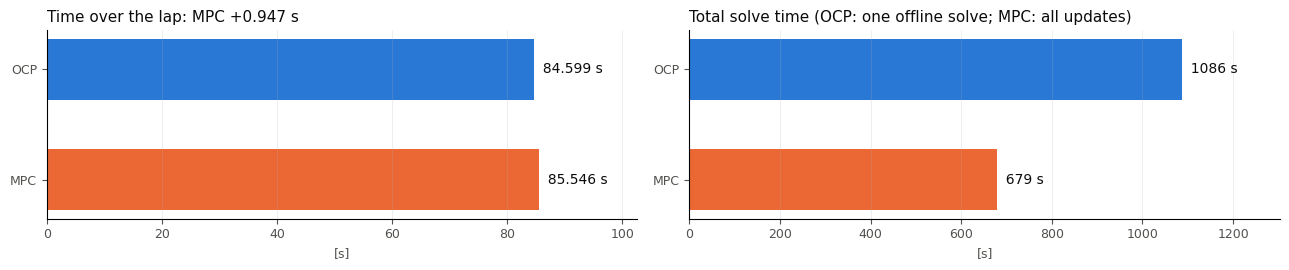

In [3]:
plot_times(comparison); plt.show()

### Driven lines
Both lines on the track, with zooms on the sections where the MPC loses the most time.

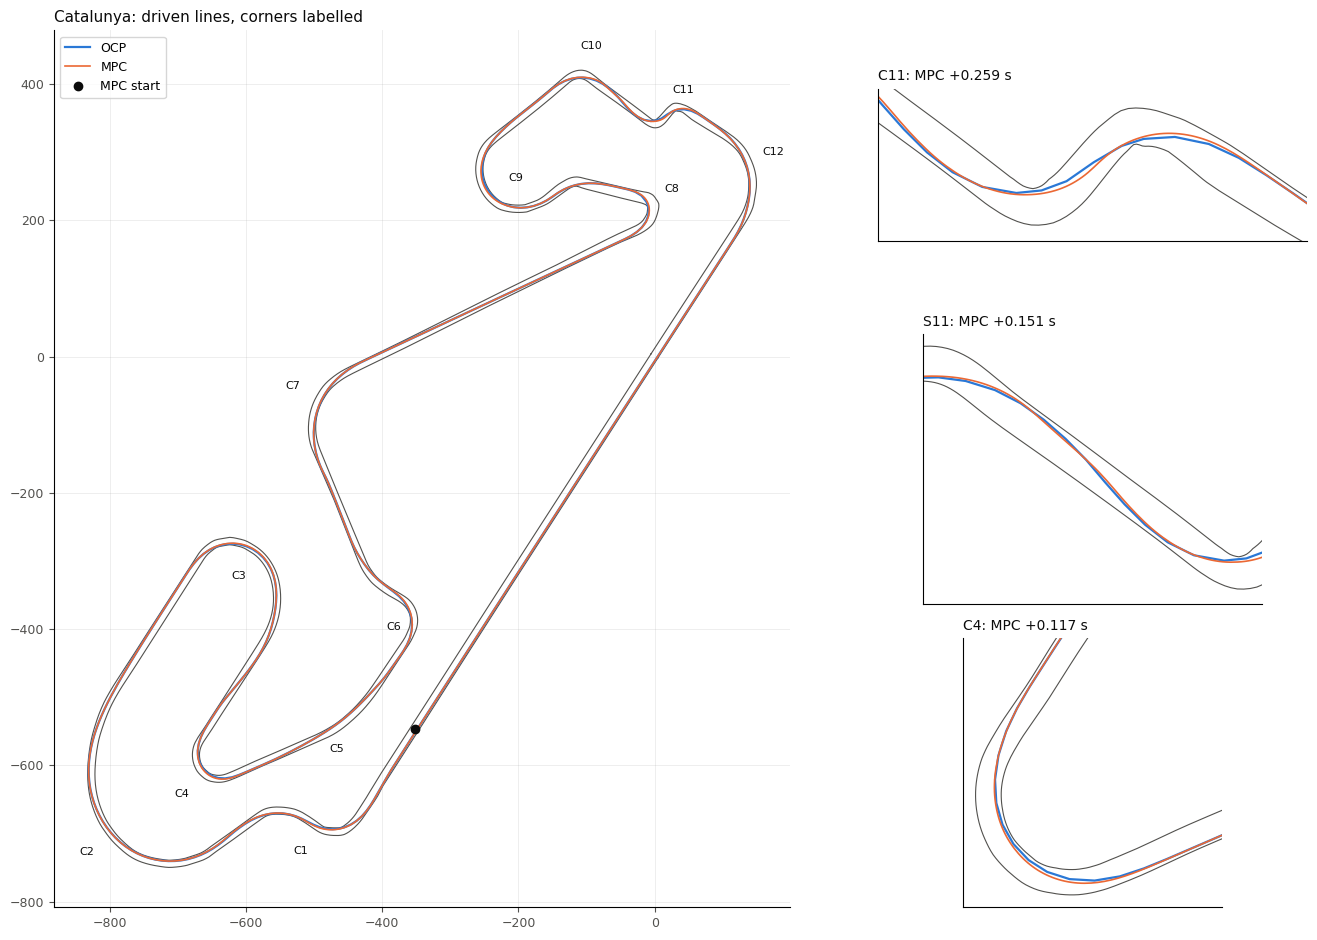

In [4]:
plot_track_overlay(comparison); plt.show()

### Traces
Both in the predictor's states, so they compare directly: left-positive, at the nominal CoG.

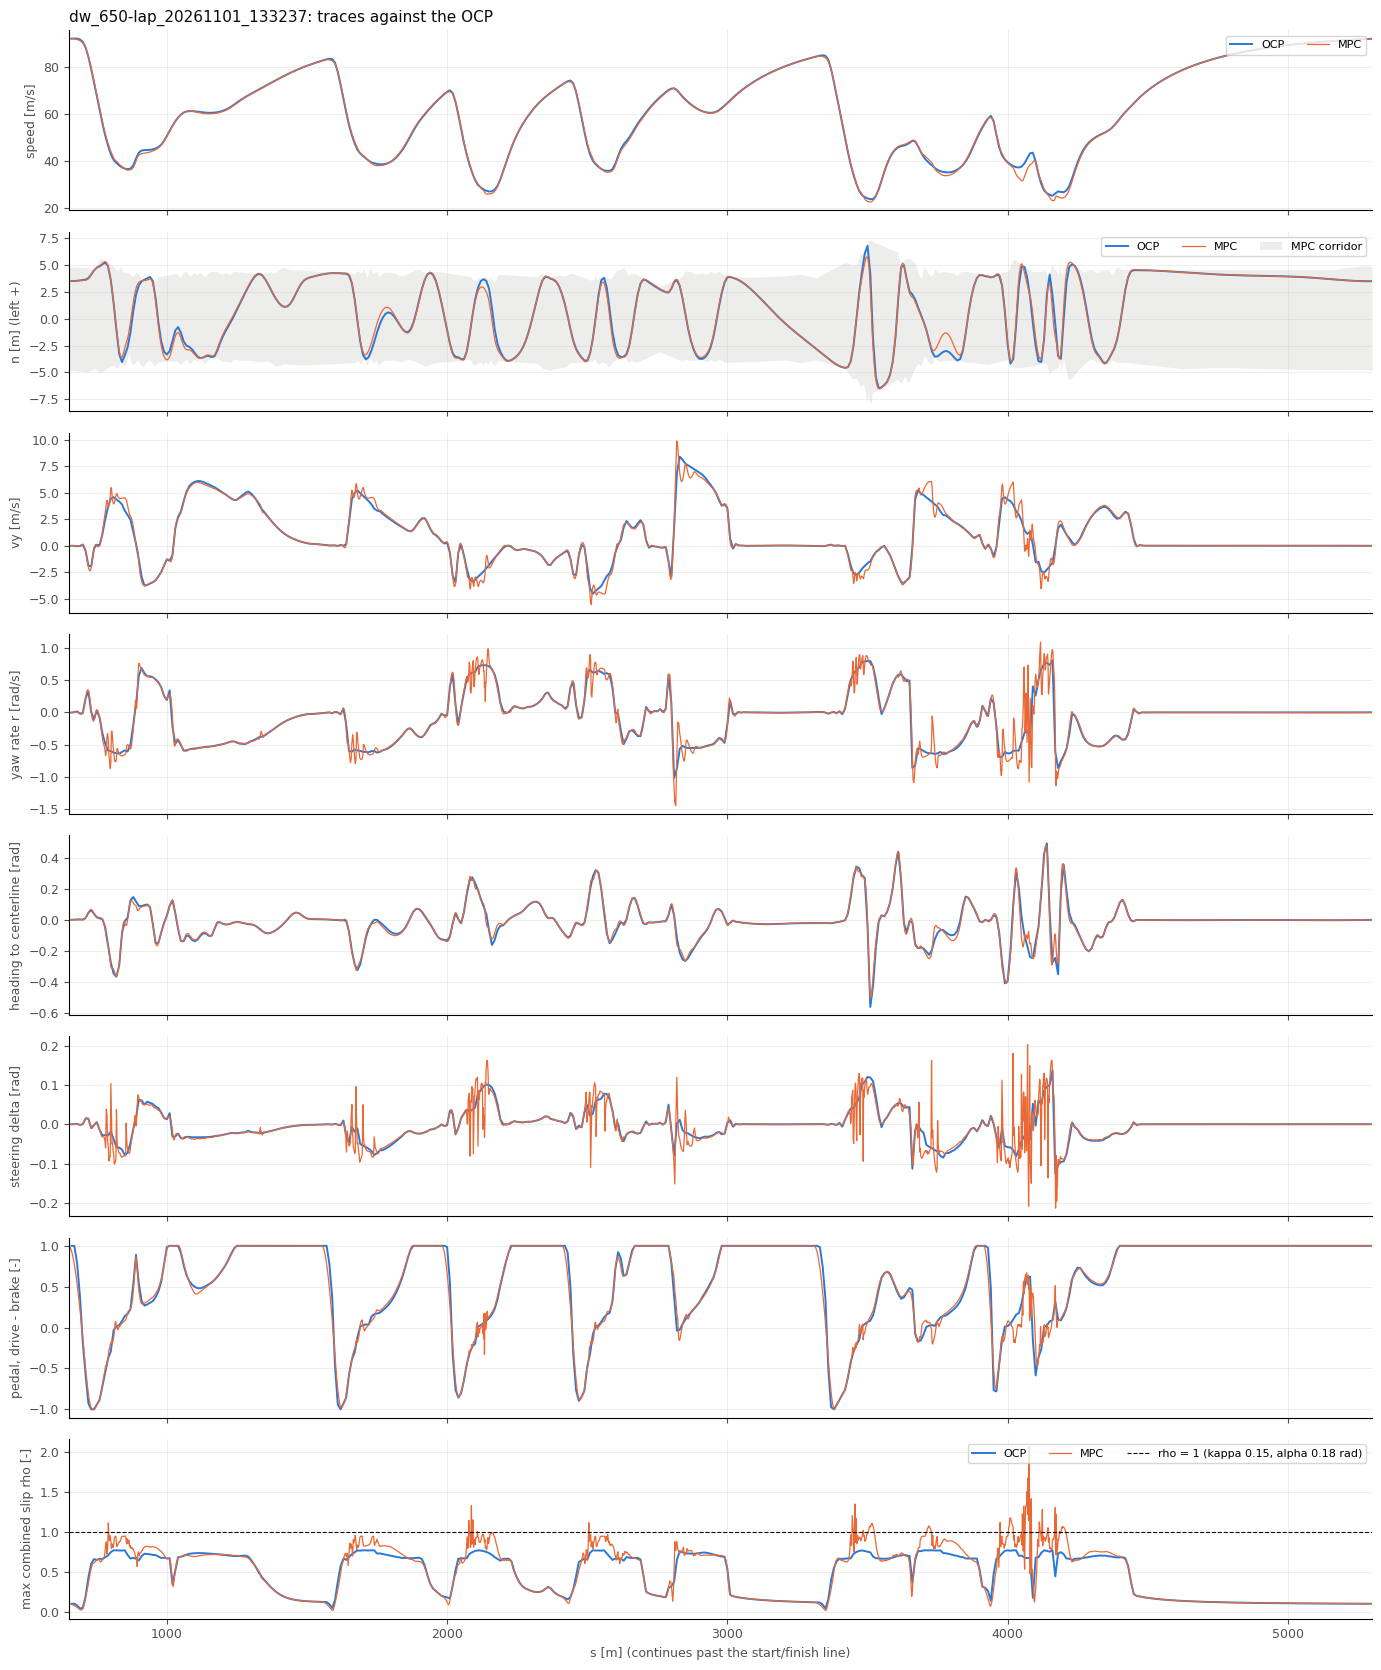

In [5]:
plot_traces(comparison); plt.show()

### Time by track section

In [6]:
print(section_table(comparison))

section  s from [m]  s to [m]   OCP [s]   MPC [s]  MPC-OCP [s]
S1              650       797     2.045     2.029       -0.016
C1              797       976     4.208     4.267       +0.059
S2              976      1046     1.332     1.336       +0.004
C2             1046      1407     5.523     5.540       +0.017
S3             1407      1666     3.453     3.445       -0.008
C3             1666      1913     5.590     5.614       +0.024
S4             1913      2068     2.507     2.497       -0.010
C4             2068      2193     3.969     4.085       +0.117
S5             2193      2327     2.668     2.660       -0.008
C5             2327      2408     1.158     1.157       -0.001
S6             2408      2508     1.591     1.581       -0.010
C6             2508      2670     3.849     3.897       +0.048
S7             2670      2836     2.572     2.586       +0.014
C7             2836      2980     2.265     2.274       +0.010
S8             2980      3444     6.454     6.449      

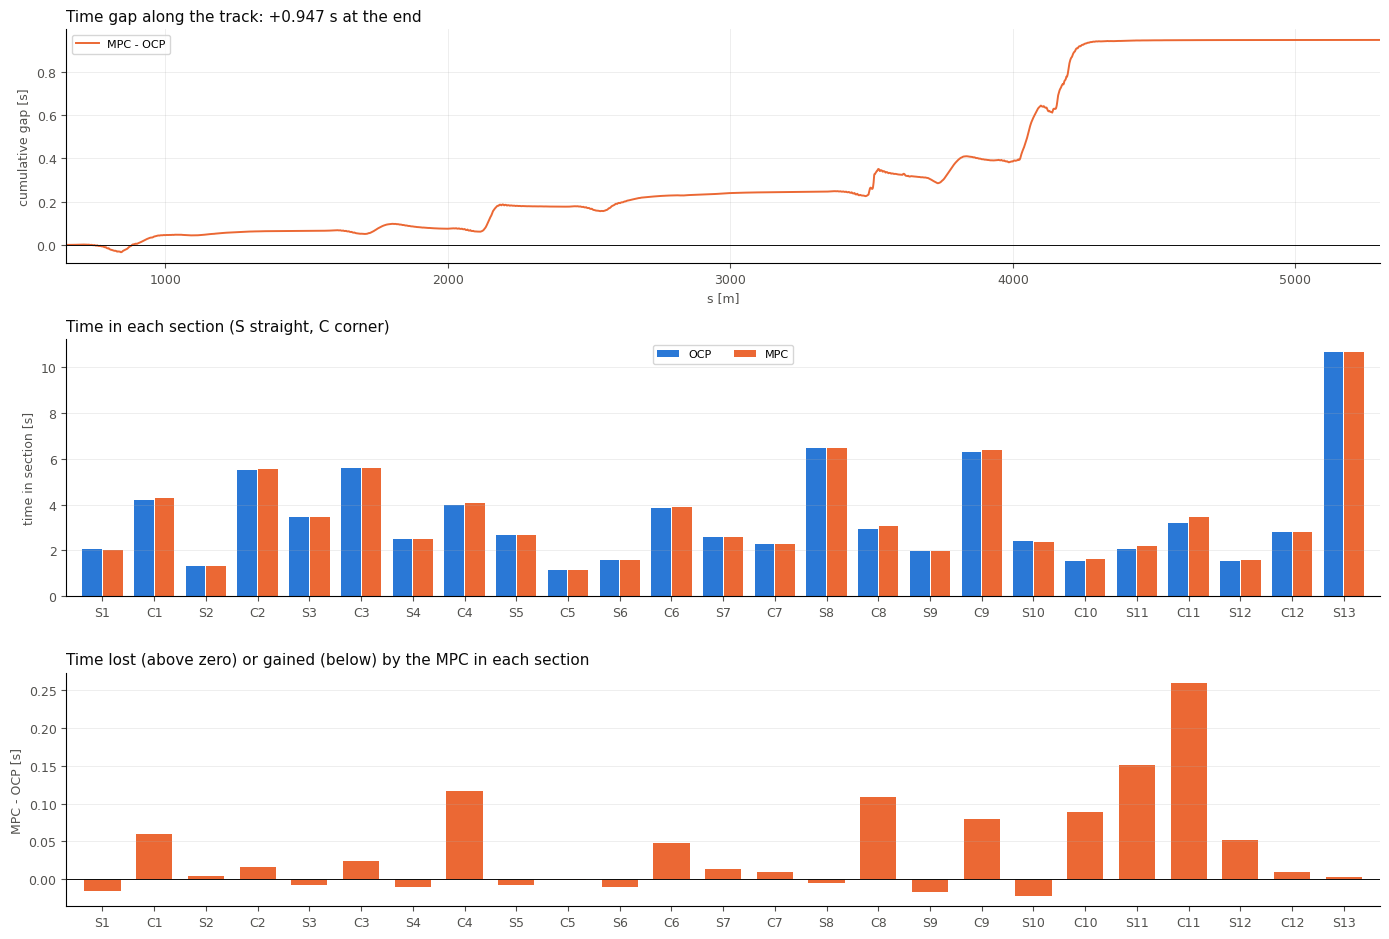

In [7]:
plot_sections(comparison); plt.show()

## Overview
Path on the track, plant states against the reference and corridor, and the solver per update. Red markers/lines are rejected windows.

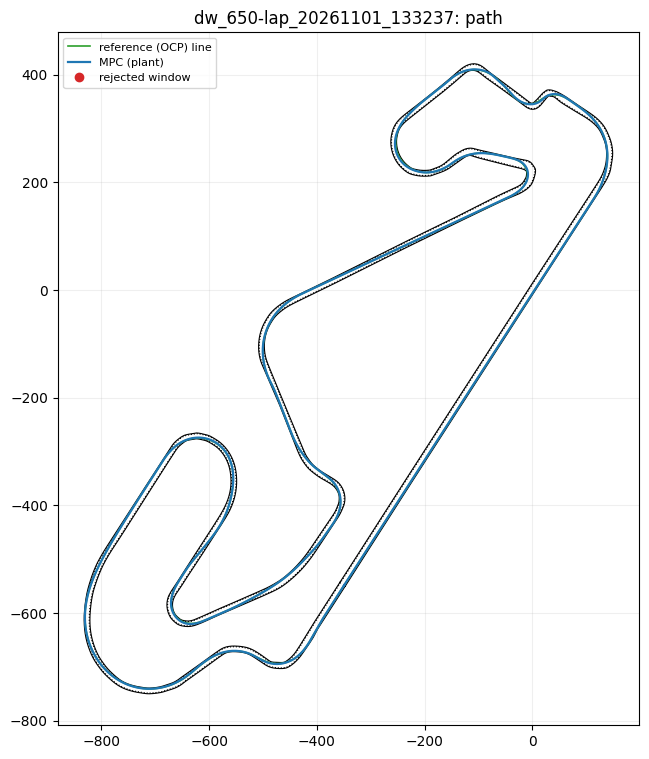

In [8]:
plot_track(run); plt.show()

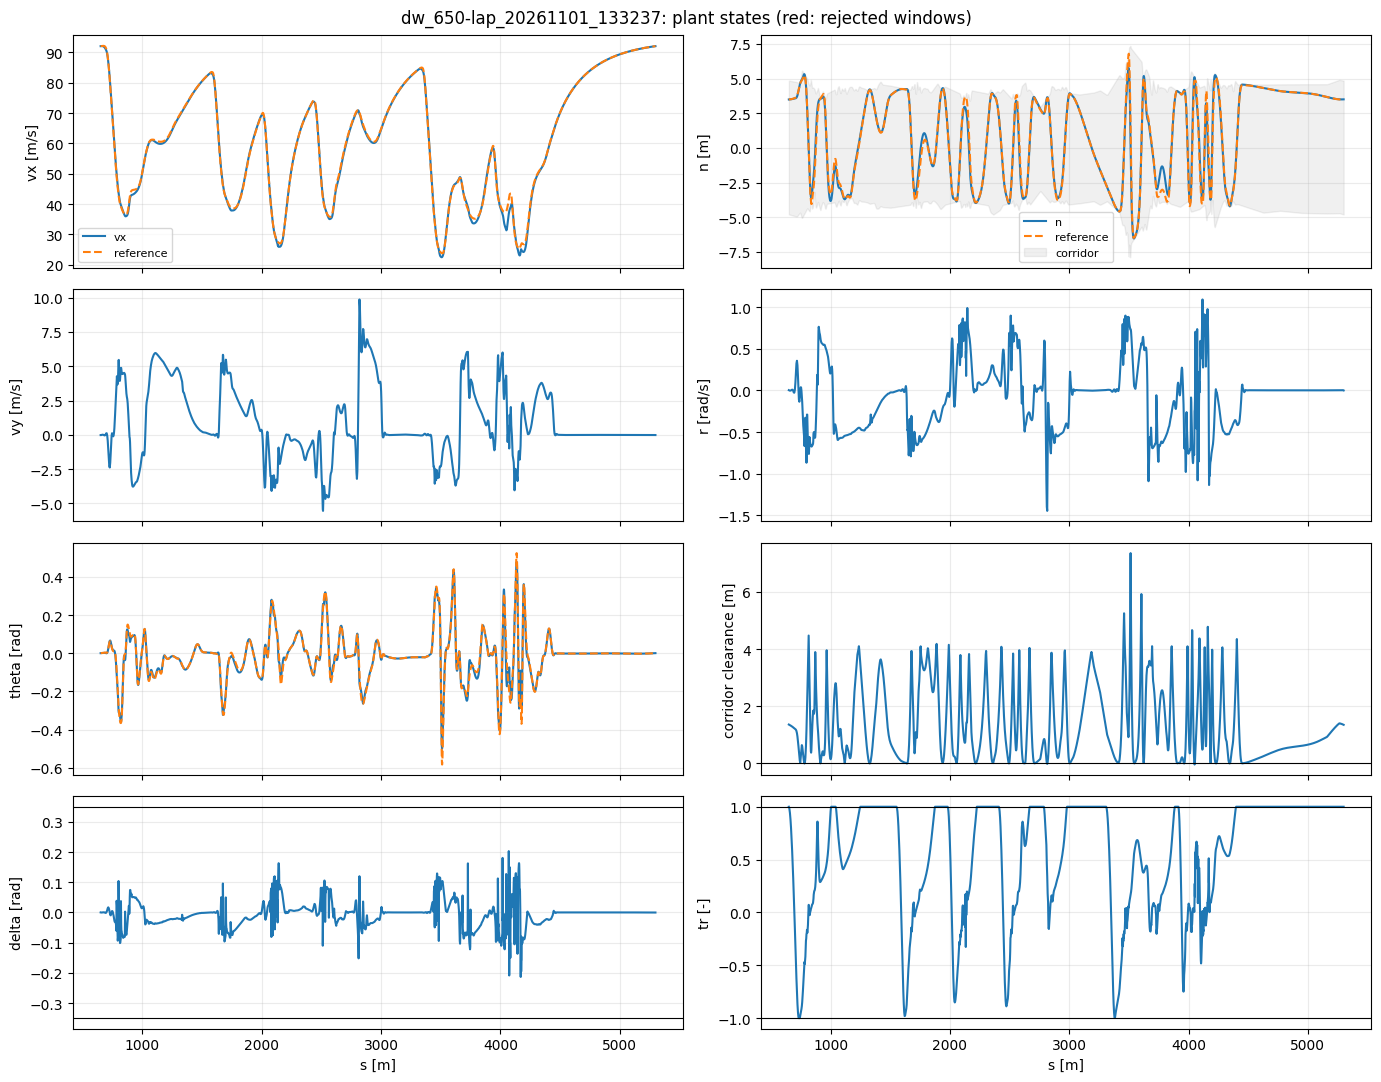

In [9]:
plot_signals(run); plt.show()

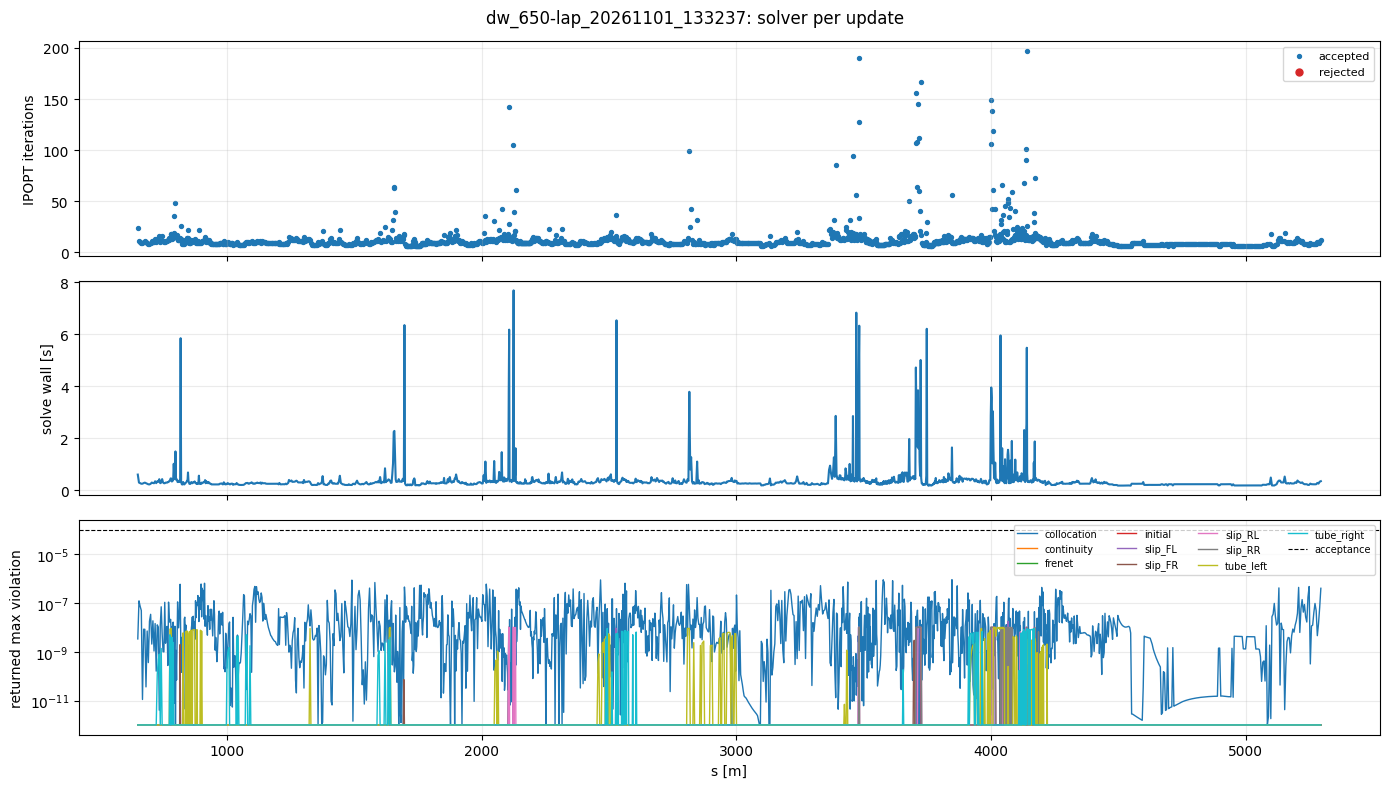

In [10]:
plot_solver(run); plt.show()

### Solver iterations along the track
One node per MPC update (every 50 ms) at the car's position, coloured by the solver iterations it took (warm and cold attempts together, log scale); rejected updates ringed in red.

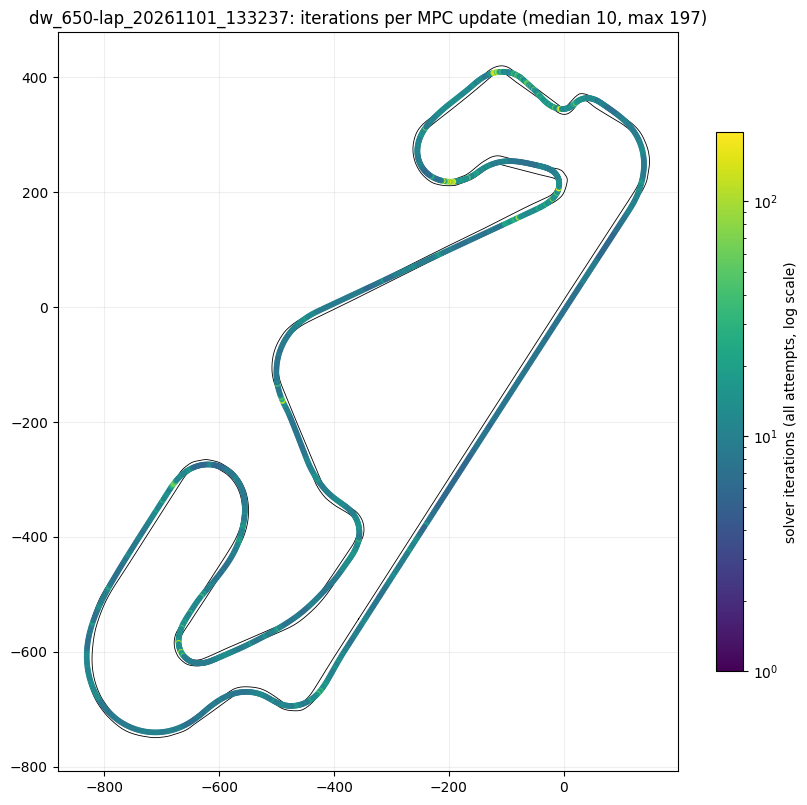

In [11]:
plot_iteration_map(run); plt.show()

## Predictor/plant mismatch
Measured minus predicted state one interval (50 ms) after each update, under the same applied rate, so this is the predictor's own error. The last panel is the plant's per-wheel combined slip.

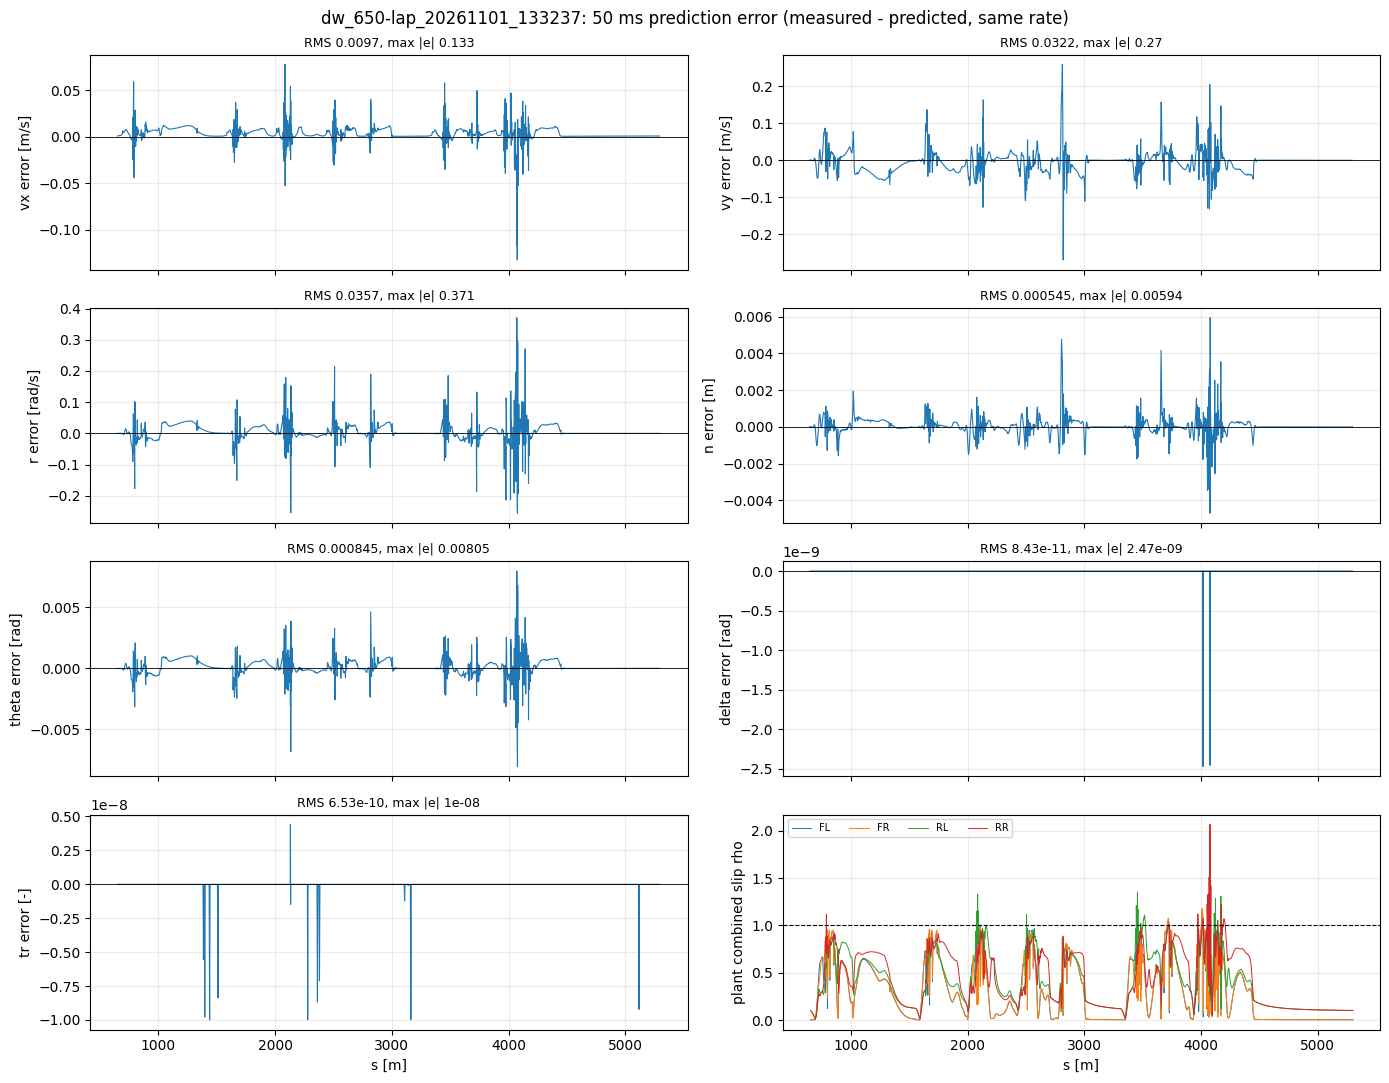

In [12]:
plot_prediction_error(run); plt.show()

## Rejected windows
For each (up to `MAX_SHOW`): the returned horizon against reference and corridor with violation by family, then the `PlotHelpers` views: IPOPT convergence, top states by violation over iterations, final profiles with bounds, violation along the horizon, and the track around the window.

In [13]:
failed = run.failed()
MAX_SHOW = 3
print(f'{len(failed)} rejected windows' + (':' if failed else ' -- nothing to debug in this run.'))
for row in failed:
    print(f"  update {row['update']:4d}  s = {row['s']:8.1f} m  {str(row['status']):30s} iterations {row['iterations']:4d}  "
          f"max violation {row['max_violation']:.2e}  worst family {max(row['violation_by_family'], key=row['violation_by_family'].get)}")

0 rejected windows -- nothing to debug in this run.


### IPOPT logs of the rejected windows
IPOPT's own iteration log (level 5) for every attempt of each rejected window, cut from `mpc/results/runs/<RUN>/ipopt.log` (runs made with `ipopt_log=True`). `print(run.ipopt_log(run.update(N)))` shows any update's log.

In [14]:
for row in failed[:MAX_SHOW]:
    print(f"################ update {row['update']}  s = {row['s']:.1f} m ################")
    print(run.ipopt_log(row))

### Plots of the rejected windows

In [15]:
for row in failed[:MAX_SHOW]:
    data = run.window(row)
    plot_window_horizon(data); plt.show()
    PlotHelpers.plot_ipopt_convergence_panels(data); plt.show()
    PlotHelpers.plot_top5_infeasibility_stackplot(data, scaled=True); plt.show()
    PlotHelpers.plot_final_iteration_profiles_with_bounds(data); plt.show()
    PlotHelpers.plot_final_violation_vs_s(data); plt.show()
    plot_track(run, window=row); plt.show()